<a href="https://colab.research.google.com/github/ek182238/CSC349/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1

Load the dataset into a Pandas DataFrame from the source repository or course mirror, assigning appropriate column names.

Explanation: I downloaded the diabetes dataset as a csv file and loaded it into a Pandas DataFrame.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('diabetes.csv')

# Task 2

Use structural inspection methods (head(), info(), describe()) to analyze feature distributions and identify non-standard placeholder values.

Explanation: I used head() to view the first 5 rows, info() to check the data types and check for null values, and describe() to see a statistical summary of each column. There are non-standard placeholder values in this dataset, which are zeros.

In [ ]:
print(df.head())
print(df.info())
print(df.describe())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768

# Task 3

Quantify and handle implicit missing values using **SimpleImputer**.

Explanation: Some columns have values that are 0 where a 0 shouldn't belong (for example, blood pressure and BMI). I replaced those with the median.

In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
cols_to_impute = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[cols_to_impute] = df[cols_to_impute].replace(0, np.nan)
print(df.isna().sum())

df[cols_to_impute] = imputer.fit_transform(df[cols_to_impute])
print(df.isna().sum())
print(df.head())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0   

# Task 4

Build a Scikit-Learn **ColumnTransformer** and **Pipeline** that applies appropriate **scaling**.

Explanation: I split the data into X (everything except the target variable) and y (the target variable). Since there are only numerical features in this dataset, I applied scaling on all of them.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

X = df.drop(columns='Outcome')
y = df['Outcome']

numeric_features = X.columns.to_list()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, numeric_features)
])

# Task 5

Train both a **Hard Voting Classifier** and a **Soft Voting Classifier** combining base models (e.g., **Logistic Regression**, **Support Vector Classifier**, and a **Decision Tree**), then evaluate their **test accuracy** and **classification reports**. Use must use appropriate **plots** to show the results.

Explanation: I trained both a hard voting classifier and a soft voting classifier using 3 base models as the estimators: logistic regression, SVC, and a decision tree. After training them, I used the prediction results to calculate the accuracy score and printed classification reports. I plotted a bar graph comparing the soft voting accuracy score to the hard voting accuracy score.

Hard voting
Accuracy score: 0.7597
Classification report:
               precision    recall  f1-score   support

           0       0.80      0.84      0.82        99
           1       0.68      0.62      0.65        55

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154


Soft voting
Accuracy score: 0.7208
Classification report:
               precision    recall  f1-score   support

           0       0.79      0.78      0.78        99
           1       0.61      0.62      0.61        55

    accuracy                           0.72       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.72      0.72      0.72       154



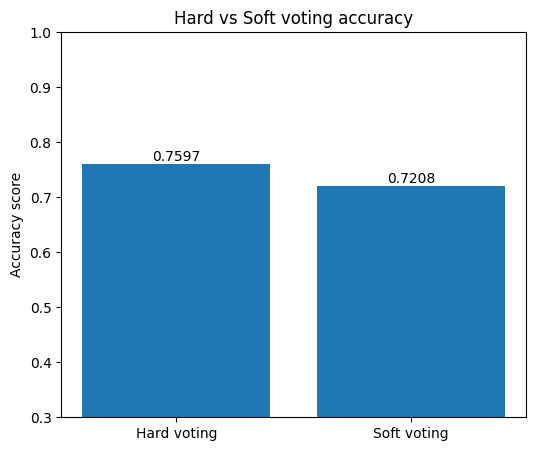

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report

log_clf = LogisticRegression(max_iter=1000, random_state=42)
svm_clf = SVC(kernel='rbf', probability=True, random_state=42)
dt_clf = DecisionTreeClassifier(random_state=42)

hard_voting_clf = VotingClassifier(estimators=[
    ('lr', log_clf),
    ('svc', svm_clf),
    ('dt', dt_clf)
], voting='hard')

soft_voting_clf = VotingClassifier(estimators=[
    ('lr', log_clf),
    ('svc', svm_clf),
    ('dt', dt_clf)
], voting='soft')

hard_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', hard_voting_clf)
])
soft_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', soft_voting_clf)
])

hard_pipeline.fit(X_train, y_train)
soft_pipeline.fit(X_train, y_train)

hard_voting_pred = hard_pipeline.predict(X_test)
soft_voting_pred = soft_pipeline.predict(X_test)

hard_voting_acc = accuracy_score(y_test, hard_voting_pred)
soft_voting_acc = accuracy_score(y_test, soft_voting_pred)

print('Hard voting')
print(f'Accuracy score: {hard_voting_acc:.4f}')
print('Classification report:\n', classification_report(y_test, hard_voting_pred))

print('\nSoft voting')
print(f'Accuracy score: {soft_voting_acc:.4f}')
print('Classification report:\n', classification_report(y_test, soft_voting_pred))

metrics = ['Hard voting', 'Soft voting']
scores = [hard_voting_acc, soft_voting_acc]

plt.figure(figsize=(6,5))
bars = plt.bar(metrics, scores)
plt.title('Hard vs Soft voting accuracy')
plt.ylabel('Accuracy score')
plt.ylim(0.30, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 4), ha='center', va='bottom')
plt.show()

# Task 6

Train a **Bagging Classifier using decision tree base estimators** with **bootstrap sampling** enabled and **out-of-bag evaluation**, and compare the OOB score against held-out test accuracy. **Plot** the accuracy results in one graph.

Explanation: When I initialized the bagging classifier, I set bootstrap and OOB score to true, which allows replacement in sampling (bootstrap aggregation) and the leftover samples could be used for testing (OOB aggregation). I plotted the OOB score and testing accuracy score on a bar graph.

OOB score: 0.7541
Accuracy score: 0.7532


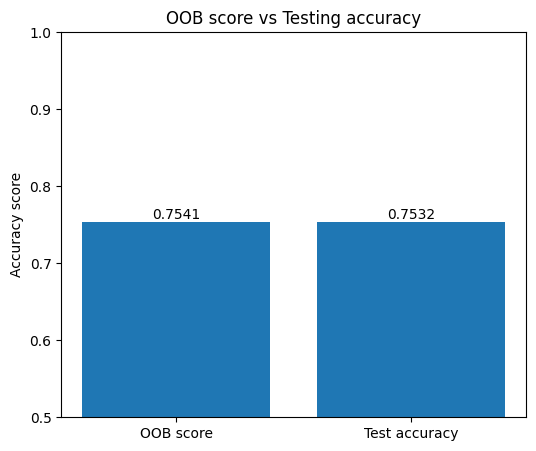

In [ ]:
from sklearn.ensemble import BaggingClassifier

bag_clf = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                            n_estimators=100,
                            bootstrap=True,
                            oob_score=True,
                            random_state=42)

bag_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', bag_clf)
])

bag_pipeline.fit(X_train, y_train)
oob = bag_clf.oob_score_
bag_pred = bag_pipeline.predict(X_test)
bag_acc = accuracy_score(y_test, bag_pred)

print(f'OOB score: {oob:.4f}')
print(f'Accuracy score: {bag_acc:.4f}')

metrics = ['OOB score', 'Test accuracy']
scores = [oob, bag_acc]

plt.figure(figsize=(6,5))
bars = plt.bar(metrics, scores)
plt.title('OOB score vs Testing accuracy')
plt.ylabel('Accuracy score')
plt.ylim(0.50, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 4), ha='center', va='bottom')
plt.show()

# Task 7

Train a **Random Forest Classifier** configured with **feature subsetting**, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

Explanation: I initialized a Random Forest Classifier and configured it with feature subsetting by setting max_features to 'sqrt'. This means that at each decision tree split, only a few features (the square root of the total amount of features) are randomly selected. I made a pandas series containing the feature importances and plotted them on a horizontal (barh) graph. Glucose, BMI, and age had the highest importances.

Accuracy score: 0.7338
Classification report:
               precision    recall  f1-score   support

           0       0.80      0.79      0.79        99
           1       0.62      0.64      0.63        55

    accuracy                           0.73       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



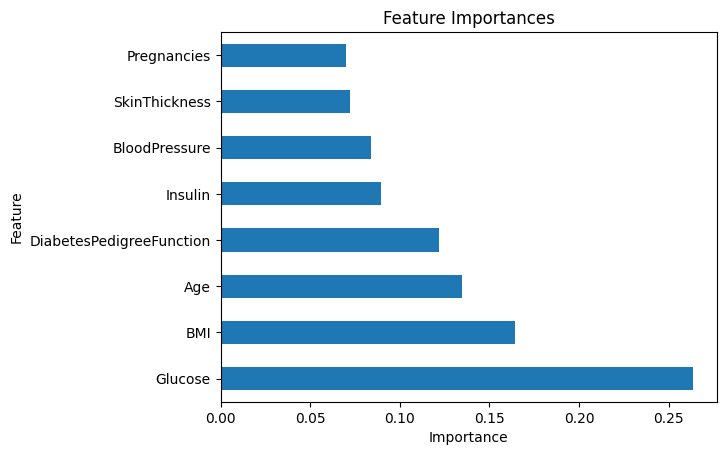

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100,
                                max_features='sqrt',
                                random_state=42)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_clf)
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)

print(f'Accuracy score: {rf_acc:.4f}')
print('Classification report:\n', classification_report(y_test, rf_pred))

importances = pd.Series(
    rf_clf.feature_importances_,
    index=numeric_features).sort_values(ascending=False)

importances.plot(kind='barh')
plt.title('Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

# Task 8

**Train an AdaBoost Classifier** utilizing **decision stumps** and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. **Plot** the results.

Explanation: I initialized an AdaBoost classifier with decision stumps (a DecisionTreeClassifier with a max depth of 1) as the estimator. I used the model to make predictions for both the training and testing data, and then I calculated their accuracy scores. I plotted the training and testing accuracy scores on a bar graph, and they are very close in value.

Training ccuracy score: 0.7883
Testing accuracy score: 0.7857


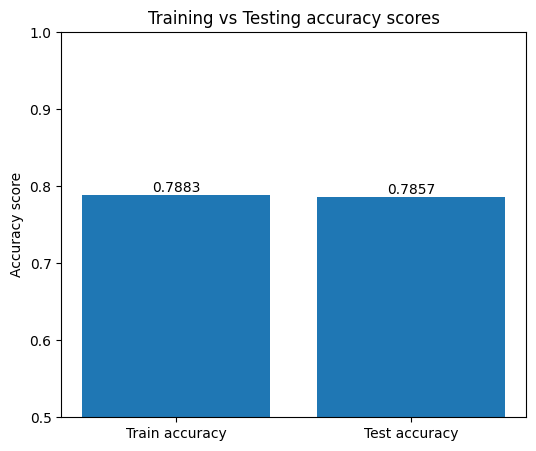

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

ada_clf = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
                             n_estimators=100,
                             learning_rate=0.5,
                             random_state=42)

ada_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', ada_clf)
])

ada_pipeline.fit(X_train, y_train)
ada_train_pred = ada_pipeline.predict(X_train)
ada_test_pred = ada_pipeline.predict(X_test)

ada_train_acc = accuracy_score(y_train, ada_train_pred)
ada_test_acc = accuracy_score(y_test, ada_test_pred)

print(f'Training ccuracy score: {ada_train_acc:.4f}')
print(f'Testing accuracy score: {ada_test_acc:.4f}')

metrics = ['Train accuracy', 'Test accuracy']
scores = [ada_train_acc, ada_test_acc]

plt.figure(figsize=(6,5))
bars = plt.bar(metrics, scores)
plt.title('Training vs Testing accuracy scores')
plt.ylabel('Accuracy score')
plt.ylim(0.50, 1)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, round(yval, 4), ha='center', va='bottom')
plt.show()